# Preparación de los datasets de gestos

Revisa y prepara los datos con los que se entrenan los tres modelos de gestos del juego:

| Gesto | Dataset | Carpeta | Uso |
|---|---|---|---|
| Ojo abierto / cerrado | **CEW** (Closed Eyes in the Wild) | `datasets/ojos_CEW` | Entrenamiento del modelo de ojos |
| Ojo abierto / cerrado | **Drowsiness dataset** (Kaggle), clases *Open/Closed* | `datasets/ojos_kaggle` | Test externo del modelo de ojos |
| Boca abierta / cerrada | **Drowsiness dataset** (Kaggle), clases *yawn/no_yawn* | `datasets/boca` | Entrenamiento del modelo de boca |
| Sonrisa / no sonrisa | **GENKI-4K** | `datasets/sonrisa` | Entrenamiento del modelo de sonrisa |

In [1]:
import os
import glob
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp

# Rutas relativas a la carpeta prototipoA
DATASETS = 'datasets'
FIGURAS = 'figuras'
os.makedirs(FIGURAS, exist_ok=True)

# Dataset -> lista de clases (una subcarpeta por clase)
CONJUNTOS = {
    'ojos_CEW':    ['abierto', 'cerrado'],
    'ojos_kaggle': ['abierto', 'cerrado'],
    'boca':        ['abierta', 'cerrada'],
    'sonrisa':     ['sonrie', 'no_sonrie'],
}

def lista_imagenes(conjunto, clase):
    """Rutas ordenadas de las imágenes de una clase de un dataset."""
    return sorted(glob.glob(os.path.join(DATASETS, conjunto, clase, '*.jpg')))

---

## 1. Recuento de muestras y tamaños

Comprueba que las clases están **balanceadas** (si una clase tuviera muchas más muestras, el clasificador tendería a predecirla siempre) y conocer el **tamaño** y si las imágenes son en **color o gris**.
> En el juego habrá que preparar los recortes de la webcam de la misma forma.

In [ ]:
resumen = {}
for conjunto, clases in CONJUNTOS.items():
    print(f'=== {conjunto}')
    for clase in clases:
        fs = lista_imagenes(conjunto, clase)
        tamanos, grises = {}, 0
        for f in fs:
            img = cv2.imread(f)
            tamanos[img.shape[:2]] = tamanos.get(img.shape[:2], 0) + 1
            if np.array_equal(img[:, :, 0], img[:, :, 1]) and np.array_equal(img[:, :, 1], img[:, :, 2]):
                grises += 1

        alturas = [h for (h, w) in tamanos for _ in range(tamanos[(h, w)])]
        anchos = [w for (h, w) in tamanos for _ in range(tamanos[(h, w)])]
        resumen[(conjunto, clase)] = len(fs)
        
        print(f'  {clase:10s} {len(fs):5d} imágenes | tamaño (alto x ancho) '
              f'min {min(alturas)}x{min(anchos)}, max {max(alturas)}x{max(anchos)} | '
              f'{"gris" if grises == len(fs) else "color"}')

=== ojos_CEW
  abierto     2462 imágenes | tamaño (alto x ancho) min 24x24, max 24x24 | gris
  cerrado     2384 imágenes | tamaño (alto x ancho) min 24x24, max 24x24 | gris
=== ojos_kaggle
  abierto      726 imágenes | tamaño (alto x ancho) min 40x50, max 1515x1514 | color
  cerrado      726 imágenes | tamaño (alto x ancho) min 54x67, max 1625x1625 | color
=== boca
  abierta      723 imágenes | tamaño (alto x ancho) min 480x640, max 480x640 | color
  cerrada      725 imágenes | tamaño (alto x ancho) min 480x640, max 480x640 | color
=== sonrisa
  sonrie      2157 imágenes | tamaño (alto x ancho) min 120x110, max 480x972 | color
  no_sonrie   1833 imágenes | tamaño (alto x ancho) min 120x120, max 480x640 | color


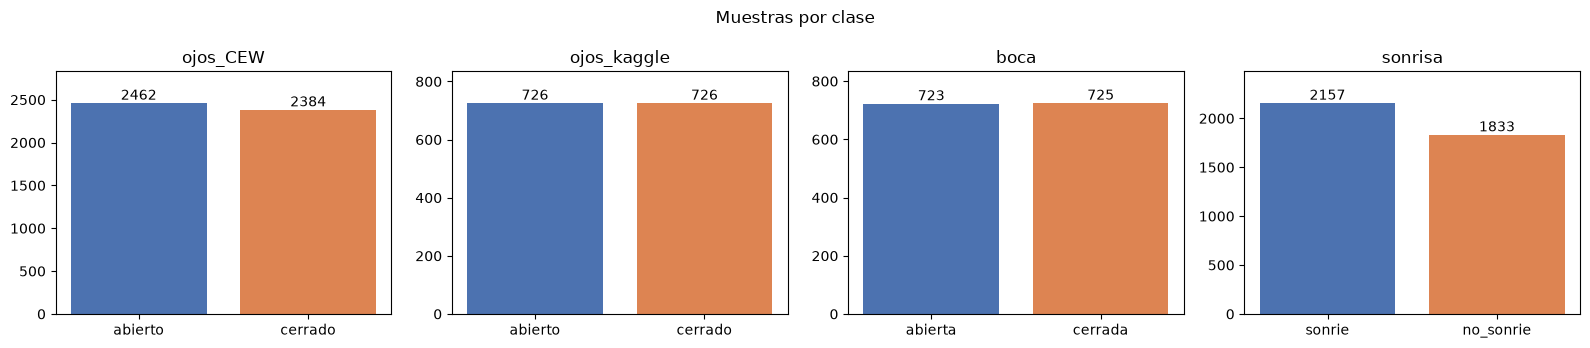

In [ ]:
# Gráfica de barras con el número de muestras por clase
fig, axs = plt.subplots(1, len(CONJUNTOS), figsize=(16, 3.5))
for ax, (conjunto, clases) in zip(axs, CONJUNTOS.items()):
    valores = [resumen[(conjunto, c)] for c in clases]
    ax.bar(clases, valores, color=['#4C72B0', '#DD8452'])
    for i, v in enumerate(valores):
        ax.text(i, v, str(v), ha='center', va='bottom')
    ax.set_title(conjunto)
    ax.set_ylim(0, max(valores) * 1.15)

plt.suptitle('Muestras por clase')
plt.tight_layout()
plt.savefig(os.path.join(FIGURAS, 'recuento_clases.png'), dpi=120)
plt.show()

---

## 2. Ejemplos de cada clase

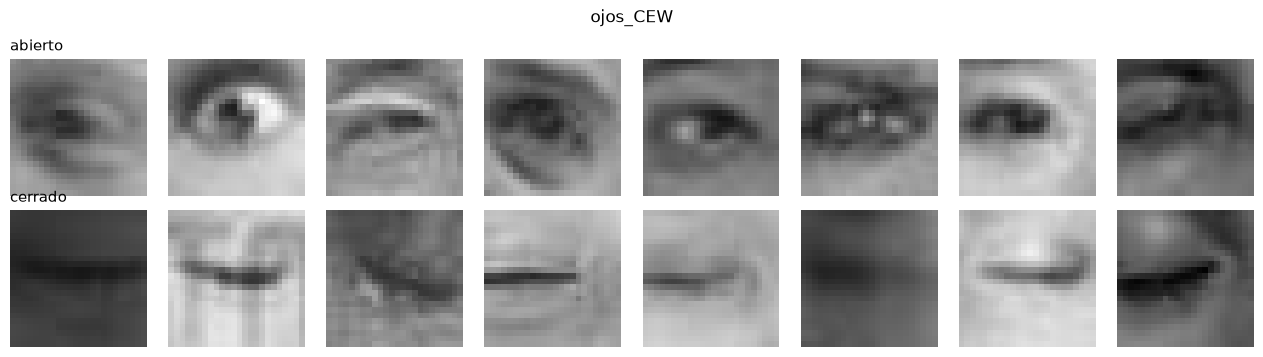

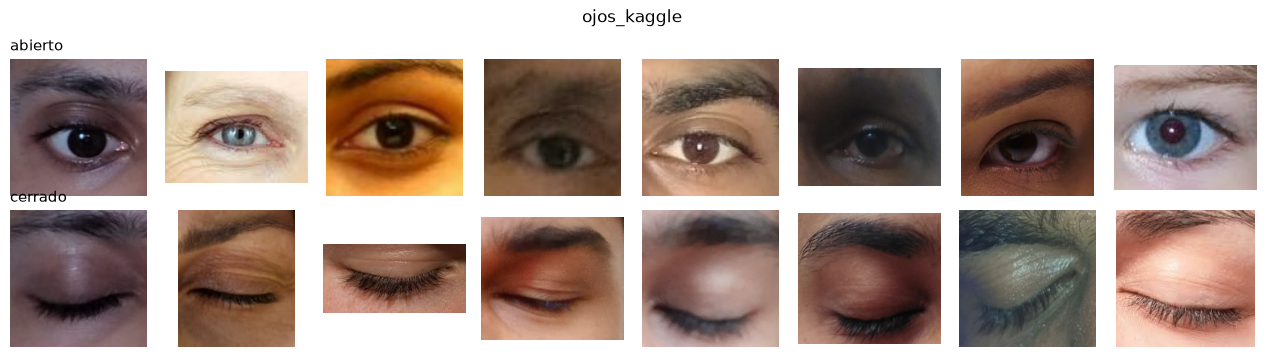

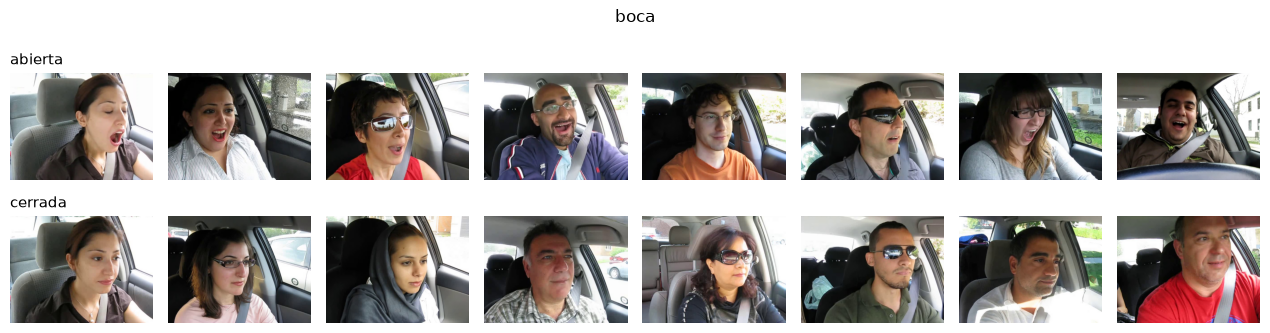

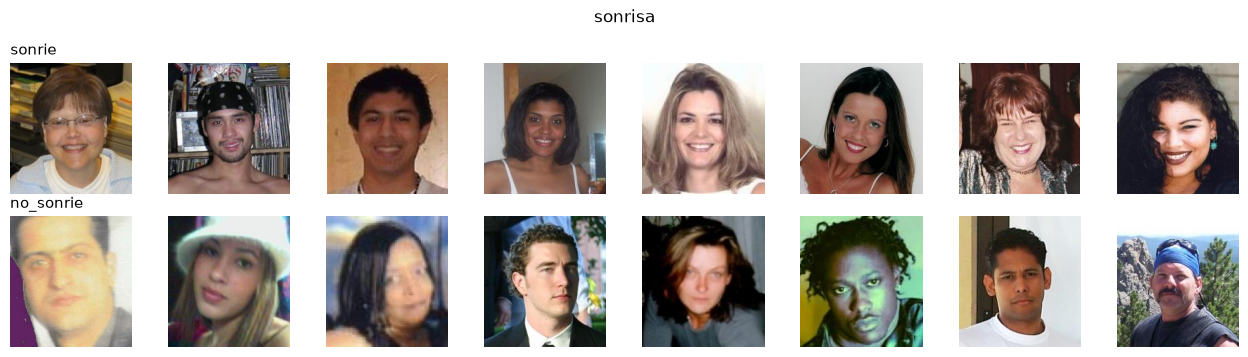

In [ ]:
def muestra_ejemplos(conjunto, n=8, tam=96):
    """Muestra n imágenes repartidas por cada clase del dataset y guarda la figura."""
    clases = CONJUNTOS[conjunto]
    fig, axs = plt.subplots(len(clases), n, figsize=(n * 1.6, len(clases) * 1.8))
    
    for fila, clase in enumerate(clases):
        fs = lista_imagenes(conjunto, clase)
        idx = np.linspace(0, len(fs) - 1, n).astype(int)
        for col, i in enumerate(idx):
            img = cv2.cvtColor(cv2.imread(fs[i]), cv2.COLOR_BGR2RGB)
            axs[fila, col].imshow(img)
            axs[fila, col].axis('off')

        axs[fila, 0].set_title(clase, loc='left', fontsize=11)

    plt.suptitle(conjunto)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURAS, f'ejemplos_{conjunto}.png'), dpi=120)
    plt.show()

for conjunto in CONJUNTOS:
    muestra_ejemplos(conjunto)

---

## 3. Recorte de la boca con MediaPipe

### 3.1 Modelo de landmarks faciales

Se usa el *Face Landmarker* de MediaPipe, que localiza 478 puntos en la cara. Si el archivo `face_landmarker.task` no está en la carpeta prototipoA, la siguiente celda lo descarga desde el repositorio oficial de modelos de MediaPipe.

In [5]:
MODELO_FACE = 'face_landmarker.task'
URL_FACE = ('https://storage.googleapis.com/mediapipe-models/face_landmarker/'
            'face_landmarker/float16/1/face_landmarker.task')

if not os.path.exists(MODELO_FACE):
    print('Descargando', MODELO_FACE, '...')
    urllib.request.urlretrieve(URL_FACE, MODELO_FACE)
print(MODELO_FACE, f'{os.path.getsize(MODELO_FACE) / 1e6:.1f} MB')

face_landmarker.task 3.8 MB


### 3.2 Recorte

De los 478 landmarks se toman los del **contorno exterior de los labios**. A partir de ellos:
1. Se calcula el centro de la boca y el lado mayor (ancho o alto) del rectángulo que la contiene.

2. Se recorta un **cuadrado** centrado en la boca con un margen del 40 % (`MARGEN = 1.4`), para que quepa la boca entera también cuando está muy abierta.

3. Si el cuadrado se sale de la imagen, se rellena replicando el borde.

4. Se redimensiona a `TAM_BOCA`×`TAM_BOCA` píxeles y se guarda en color.

In [6]:
# Índices de MediaPipe del contorno exterior de los labios
LABIOS = [61, 146, 91, 181, 84, 17, 314, 405, 321, 375,
          291, 185, 40, 39, 37, 0, 267, 269, 270, 409]
MARGEN = 1.4
TAM_BOCA = 64

def recorta_boca(img_bgr, landmarks, margen=MARGEN, tam=TAM_BOCA):
    """Recorte cuadrado de la boca centrado en los labios, con un 40 % de margen, a tam x tam."""
    h, w = img_bgr.shape[:2]
    p = np.array([[landmarks[i].x * w, landmarks[i].y * h] for i in LABIOS])
    centro = p.mean(axis=0)
    lado = int(max(np.ptp(p[:, 0]), np.ptp(p[:, 1])) * margen)
    x0, y0 = int(centro[0] - lado / 2), int(centro[1] - lado / 2)
    # Relleno por si el recorte se sale de la imagen
    pad = cv2.copyMakeBorder(img_bgr, lado, lado, lado, lado, cv2.BORDER_REPLICATE)
    recorte = pad[y0 + lado:y0 + 2 * lado, x0 + lado:x0 + 2 * lado]
    return cv2.resize(recorte, (tam, tam), interpolation=cv2.INTER_AREA)

opciones = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=MODELO_FACE),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=1,
)

In [ ]:
# De boca y sonrisa
sin_cara = {}
with mp.tasks.vision.FaceLandmarker.create_from_options(opciones) as detector:
    for conjunto in ['boca', 'sonrisa']:
        for clase in CONJUNTOS[conjunto]:
            destino = os.path.join(DATASETS, f'{conjunto}_recortes', clase)
            os.makedirs(destino, exist_ok=True)
            fs = lista_imagenes(conjunto, clase)
            fallos, nuevos = [], 0

            for f in fs:
                salida = os.path.join(destino, os.path.basename(f))
                if os.path.exists(salida):
                    continue
                
                img = cv2.imread(f)
                rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                res = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
                
                if not res.face_landmarks:
                    fallos.append(f)
                    continue
                
                cv2.imwrite(salida, recorta_boca(img, res.face_landmarks[0]))
                nuevos += 1
            
            sin_cara[(conjunto, clase)] = fallos
            total = len(os.listdir(destino))
            
            print(f'{conjunto}/{clase}: {total} recortes ({nuevos} nuevos), '
                  f'{len(fallos)} imágenes sin cara detectada')

boca/abierta: 709 recortes (0 nuevos), 14 imágenes sin cara detectada
boca/cerrada: 720 recortes (0 nuevos), 5 imágenes sin cara detectada
sonrisa/sonrie: 2139 recortes (0 nuevos), 18 imágenes sin cara detectada
sonrisa/no_sonrie: 1817 recortes (0 nuevos), 16 imágenes sin cara detectada


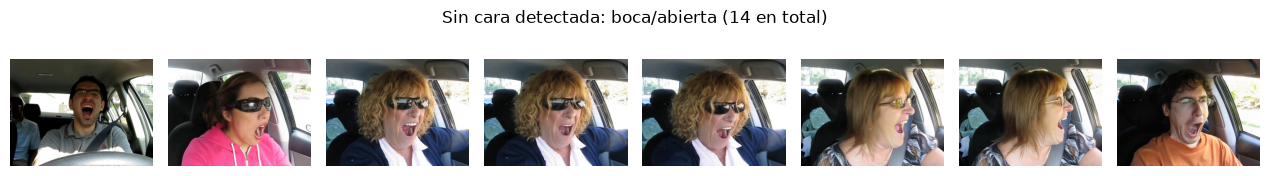

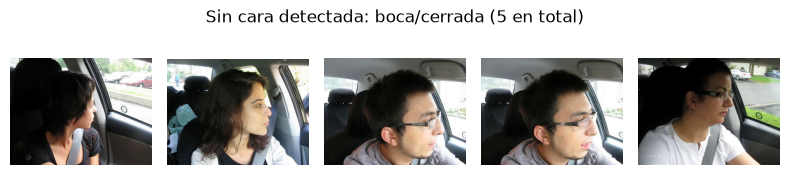

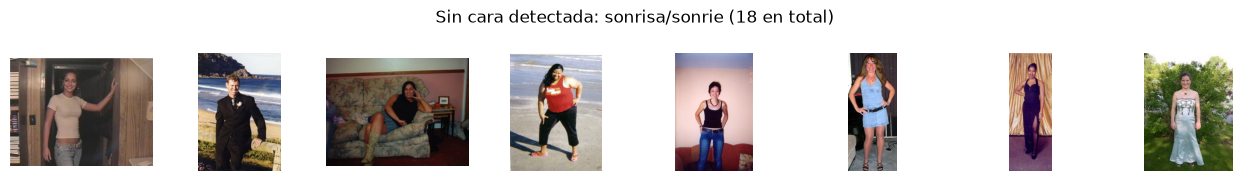

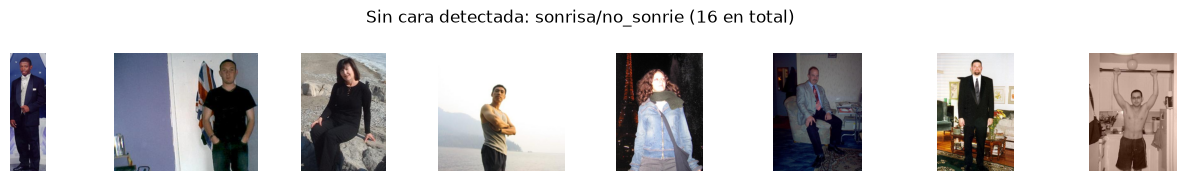

In [ ]:
# Imágenes en las que MediaPipe no encontró cara se descartan
for (conjunto, clase), fallos in sin_cara.items():
    if fallos:
        n = min(len(fallos), 8)
        fig, axs = plt.subplots(1, n, figsize=(n * 1.6, 1.8), squeeze=False)
        for ax, f in zip(axs[0], fallos[:n]):
            ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
            ax.axis('off')
        plt.suptitle(f'Sin cara detectada: {conjunto}/{clase} ({len(fallos)} en total)')
        plt.tight_layout()
        plt.show()

### 3.3 Resultado de los recortes

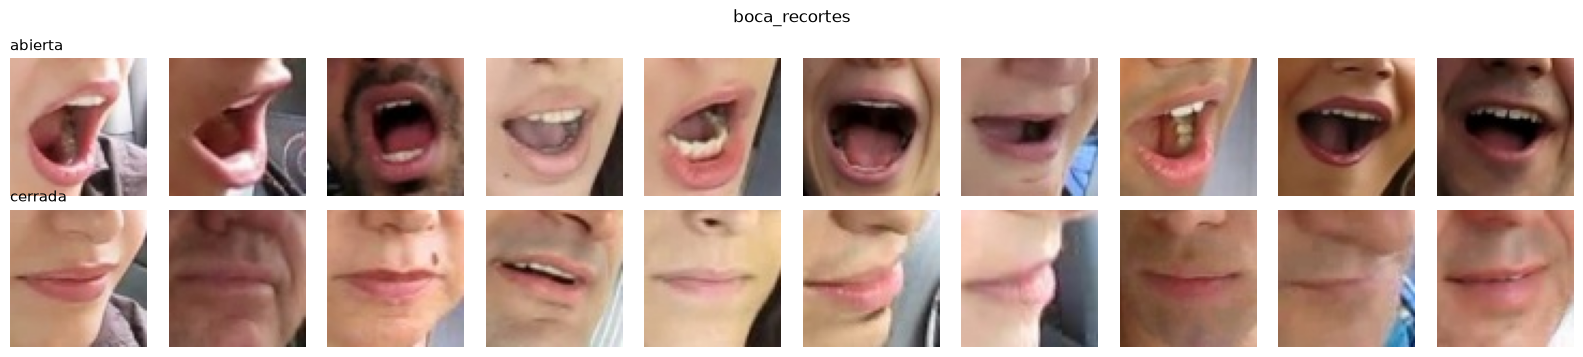

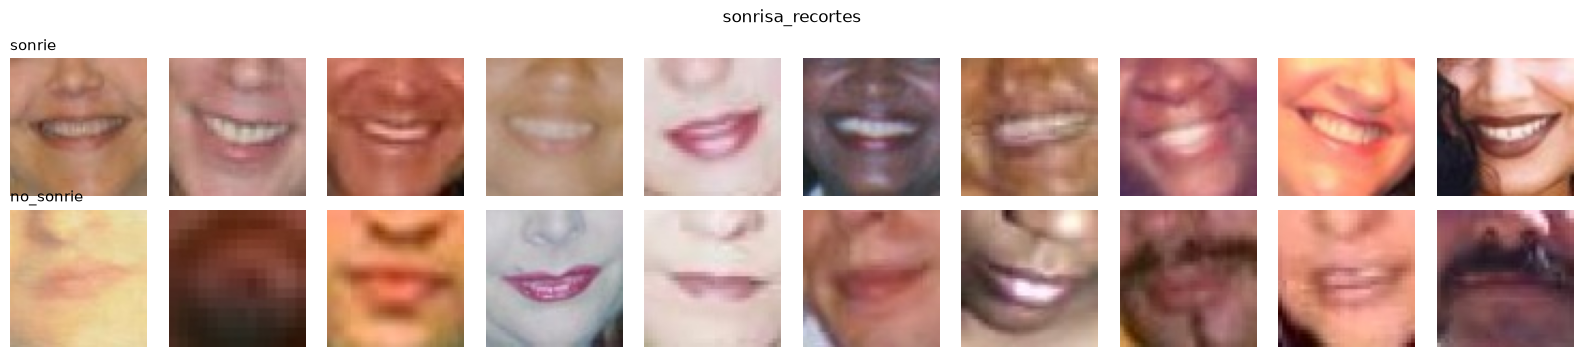

In [9]:
for conjunto in ['boca_recortes', 'sonrisa_recortes']:
    CONJUNTOS[conjunto] = CONJUNTOS[conjunto.replace('_recortes', '')]
    muestra_ejemplos(conjunto, n=10)

---

## 4. Conclusiones

- Los tres conjuntos tienen las clases **balanceadas**, así que la *accuracy* es una métrica razonable, aunque se mostrarán también precisión, *recall* y matriz de confusión.

- En CEW el ojo izquierdo y el derecho de una misma persona no deben quedar uno en entrenamiento y otro en test, y en `boca` hay muchos fotogramas de las mismas personas. Si se reparten al azar, el resultado del k-fold saldrá optimista. En los cuadernos de entrenamiento se agruparán las muestras por persona al dividir (`StratifiedGroupKFold`).

---